In [1]:
# Imports/Setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid', palette='Dark2')

In [2]:
df = pd.read_csv("../data/raw/marketing_AB.csv")
df.head()

,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour
0,0,1069124,ad,False,130,Monday,20
1,1,1119715,ad,False,93,Tuesday,22
2,2,1144181,ad,False,21,Tuesday,18
3,3,1435133,ad,False,355,Tuesday,10
4,4,1015700,ad,False,276,Friday,14


In [3]:
df = df.drop(columns='Unnamed: 0')
df = df.rename(columns={'user id': 'user_id', 'test group':'test_group', 'total ads': 'total_ads', 
                        'most ads day':'most_ads_day', 'most ads hour':'most_ads_hour'})
df.columns.to_list()

['user_id',
 'test_group',
 'converted',
 'total_ads',
 'most_ads_day',
 'most_ads_hour']

In [4]:
df.info()
df.shape

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 588101 entries, 0 to 588100
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   user_id        588101 non-null  int64 
 1   test_group     588101 non-null  object
 2   converted      588101 non-null  bool  
 3   total_ads      588101 non-null  int64 
 4   most_ads_day   588101 non-null  object
 5   most_ads_hour  588101 non-null  int64 
dtypes: bool(1), int64(3), object(2)
memory usage: 23.0+ MB


(588101, 6)

In [5]:
# check for duplicates
df['user_id'].duplicated().sum()

0

In [6]:
df[['total_ads','most_ads_hour']].describe()
# most_ads_hours runs 0-23 as expected. However, total_ads is heavily rihgt-skewed. Keeping in mind for covarate balance.

,total_ads,most_ads_hour
count,588101.000000,588101.000000
mean,24.820876,14.469061
std,43.715181,4.834634
min,1.000000,0.000000
25%,4.000000,11.000000
50%,13.000000,14.000000
75%,27.000000,18.000000
max,2065.000000,23.000000


In [7]:
df["test_group"].value_counts(normalize=True)

test_group
ad     0.96
psa    0.04
Name: proportion, dtype: float64

In [8]:
df.groupby("test_group")["converted"].mean()

test_group
ad     0.025547
psa    0.017854
Name: converted, dtype: float64

## Holdout analysis

**Estimand:** effect of the ad *relative to a PSA* (control saw a PSA, not nothing). **Assumes:** random assignment, SUTVA, no differential attrition. No duplicate `user_id`s (checked above).

In [9]:
import sys; sys.path.insert(0, '..')
from src.holdout import *

summary = group_summary(df)
summary

,n,conversions,rate
test_group,,,
ad,564577,14423,0.025547
psa,23524,420,0.017854


### Covariate balance
Chi-square p-values are tiny because n is huge; look at effect size (Cramér's V ≈ 0.02) instead. 'most_ads_day/hour' may be post-treatment, so treat as a sanity check.

In [10]:
for col in ['most_ads_day', 'most_ads_hour']:
    r = chi2_balance(df, col)
    print(col, 'chi2 =', round(r['chi2'], 1), 'p =', r['p_value'], 'Cramers V =', round((r['chi2'] / len(df)) ** 0.5, 4))
balance_table(df, 'most_ads_day').round(4)

most_ads_day chi2 = 235.6 p = 4.849067664297987e-48 Cramers V = 0.02
most_ads_hour chi2 = 192.3 p = 1.094573971081402e-28 Cramers V = 0.0181


test_group,ad,psa
most_ads_day,,
Friday,0.1573,0.1617
Monday,0.1480,0.1489
Saturday,0.1396,0.1215
Sunday,0.1458,0.1300
Thursday,0.1401,0.1660
Tuesday,0.1321,0.1236
Wednesday,0.1371,0.1484


### Test and CI for the lift

In [11]:
x1, n1 = int(summary.loc['ad', 'conversions']), int(summary.loc['ad', 'n'])
x0, n0 = int(summary.loc['psa', 'conversions']), int(summary.loc['psa', 'n'])
z = two_prop_ztest(x1, n1, x0, n0)
draws, boot_ci = bootstrap_diff(x1, n1, x0, n0)
print('lift (pp):', round(z['diff'] * 100, 3), '| z =', round(z['z'], 2), '| p =', z['p_value'])
print('Wald CI (pp):', [round(v * 100, 3) for v in z['wald_ci']])
print('Bootstrap CI (pp):', [round(v * 100, 3) for v in boot_ci])

lift (pp): 0.769 | z = 7.37 | p = 1.7052807161559727e-13
Wald CI (pp): [0.595, 0.943]
Bootstrap CI (pp): [0.597, 0.942]


### Attributed vs incremental

In [12]:
inc = incrementality(x1 / n1, x0 / n0, n1, boot_ci)
inc

{'attributed': 14423.0,
 'incremental': 4342.982145893556,
 'incremental_ci': (3368.9556984356404, 5319.008919614011),
 'incremental_share': 0.3011150347288051}

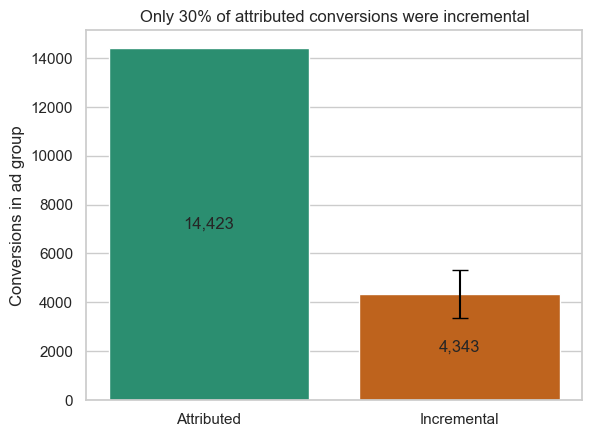

In [13]:
attributed, incremental = inc['attributed'], inc['incremental']
lo, hi = inc['incremental_ci']

labels = ['Attributed', 'Incremental']
ax = sns.barplot(x=labels, y=[attributed, incremental], hue=labels, legend=False)
for bars in ax.containers:
    ax.bar_label(bars, label_type='center', fmt='{:,.0f}')
ax.errorbar(1, incremental, yerr=[[incremental - lo], [hi - incremental]], color='black', capsize=6)
ax.set(ylabel='Conversions in ad group',
       title=f'Only {incremental / attributed:.0%} of attributed conversions were incremental')
plt.savefig('../figures/attributed_vs_incremental.png', dpi=150, bbox_inches='tight')